In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv("/content/heart_failure_clinical_records_dataset.csv")

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       299 non-null    float64
 1   anaemia                   299 non-null    int64  
 2   creatinine_phosphokinase  299 non-null    int64  
 3   diabetes                  299 non-null    int64  
 4   ejection_fraction         299 non-null    int64  
 5   high_blood_pressure       299 non-null    int64  
 6   platelets                 299 non-null    float64
 7   serum_creatinine          299 non-null    float64
 8   serum_sodium              299 non-null    int64  
 9   sex                       299 non-null    int64  
 10  smoking                   299 non-null    int64  
 11  time                      299 non-null    int64  
 12  DEATH_EVENT               299 non-null    int64  
dtypes: float64(3), int64(10)
memory usage: 30.5 KB


In [ ]:
df.describe()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
count,299.000000,299.000000,299.000000,299.000000,299.000000,299.000000,299.000000,299.00000,299.000000,299.000000,299.00000,299.000000,299.00000
mean,60.833893,0.431438,581.839465,0.418060,38.083612,0.351171,263358.029264,1.39388,136.625418,0.648829,0.32107,130.260870,0.32107
std,11.894809,0.496107,970.287881,0.494067,11.834841,0.478136,97804.236869,1.03451,4.412477,0.478136,0.46767,77.614208,0.46767
min,40.000000,0.000000,23.000000,0.000000,14.000000,0.000000,25100.000000,0.50000,113.000000,0.000000,0.00000,4.000000,0.00000
25%,51.000000,0.000000,116.500000,0.000000,30.000000,0.000000,212500.000000,0.90000,134.000000,0.000000,0.00000,73.000000,0.00000
50%,60.000000,0.000000,250.000000,0.000000,38.000000,0.000000,262000.000000,1.10000,137.000000,1.000000,0.00000,115.000000,0.00000
75%,70.000000,1.000000,582.000000,1.000000,45.000000,1.000000,303500.000000,1.40000,140.000000,1.000000,1.00000,203.000000,1.00000
max,95.000000,1.000000,7861.000000,1.000000,80.000000,1.000000,850000.000000,9.40000,148.000000,1.000000,1.00000,285.000000,1.00000


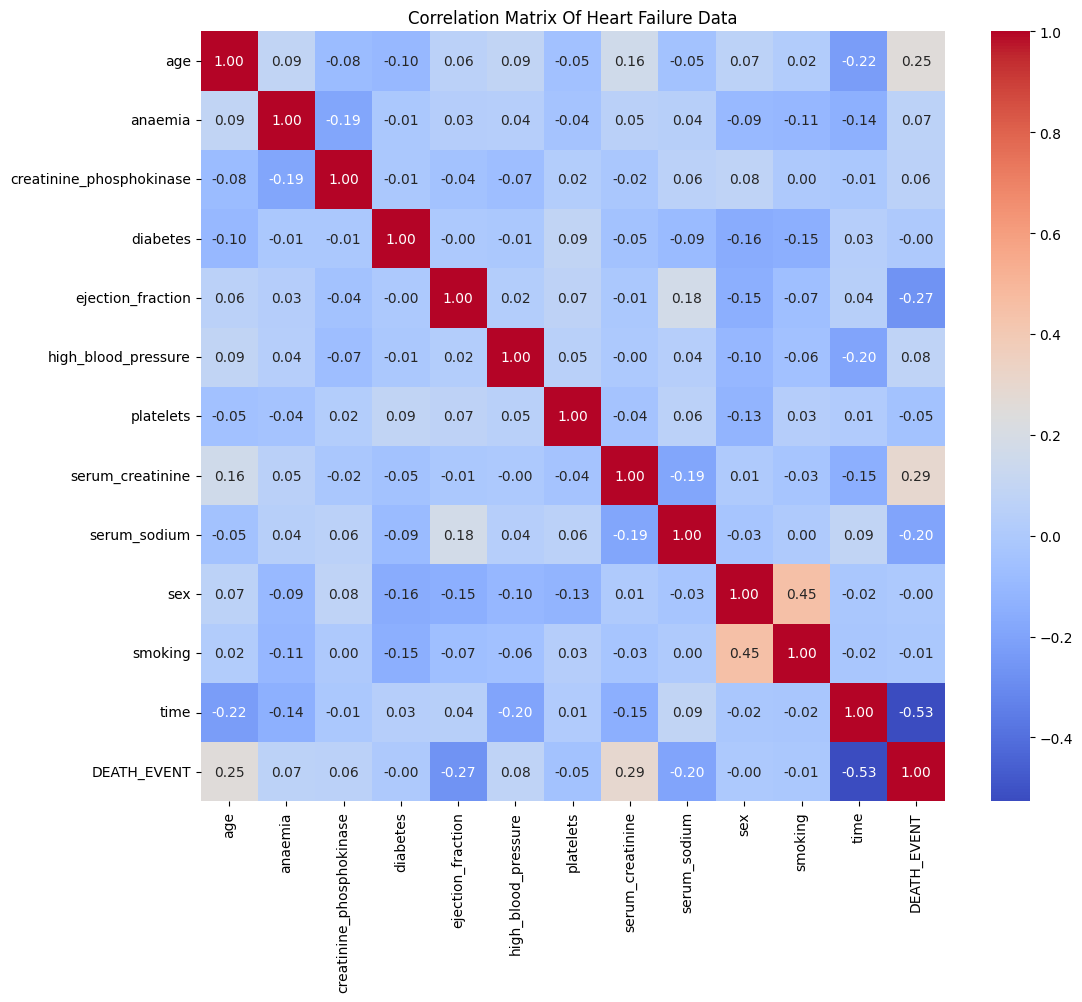

In [ ]:
plt.figure(figsize=(12,10))
sns.heatmap(df.corr(),annot=True,cmap="coolwarm",fmt='.2f')
plt.title('Correlation Matrix Of Heart Failure Data')
plt.show()

In [ ]:
x=df.drop('DEATH_EVENT',axis=1)
y=df['DEATH_EVENT']
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)
print("training set size:",x_train.shape)
print("testing set size:",x_test.shape)

training set size: (239, 12)
testing set size: (60, 12)


In [ ]:
from sklearn.linear_model import LogisticRegression
model=LogisticRegression(C=1000)
model.fit(x_train,y_train)
y_pred=model.predict(x_test)
print("Model Training Complete")

Model Training Complete


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
accuracy= accuracy_score(y_test,y_pred)
print(f"Model Accuuracy:{accuracy*100:.2f}%")
print("\nclassification Report:")
print(classification_report(y_test,y_pred))

Model Accuuracy:80.00%

classification Report:
              precision    recall  f1-score   support

           0       0.76      0.97      0.85        35
           1       0.93      0.56      0.70        25

    accuracy                           0.80        60
   macro avg       0.84      0.77      0.77        60
weighted avg       0.83      0.80      0.79        60



In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

scaler=StandardScaler()
x_train_scaled=scaler.fit_transform(x_train) # Corrected: used x_train
x_test_scaled=scaler.transform(x_test) # Corrected: scaled x_test and assigned to x_test_scaled

model_scaled=LogisticRegression()
model_scaled.fit(x_train_scaled,y_train)
y_pred_scaled=model_scaled.predict(x_test_scaled)
print(f"New Model Accuracy:{accuracy_score(y_test,y_pred_scaled)}")

New Model Accuracy:0.8


In [ ]:
coefficients = pd.DataFrame({'Feature':x.columns,'Coefficient':model_scaled.coef_[0]}) # Access coef_ attribute and select the first (and only) row for single-target classification
coefficients = coefficients.sort_values(by='Coefficient',ascending=False)
print(coefficients)

                     Feature  Coefficient
7           serum_creatinine     0.701778
0                        age     0.660645
3                   diabetes     0.164116
2   creatinine_phosphokinase     0.110553
10                   smoking     0.071272
1                    anaemia    -0.051535
5        high_blood_pressure    -0.060786
6                  platelets    -0.170253
8               serum_sodium    -0.260489
9                        sex    -0.362421
4          ejection_fraction    -0.876051
11                      time    -1.651880
